In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# Replicar limpieza de la Actividad 1 (llenar nulos de bmi con su media)
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

# Guardar la columna objetivo para la validación de la Sección 4
stroke_real = df['stroke'].copy()

# Eliminar 'id' (no sirve para machine learning) y 'stroke' (el algoritmo debe ser ciego)
df_clean = df.drop(columns=['id', 'stroke'])

# 2. Seleccionar las variables numéricas y continuas clave
features = ['age', 'avg_glucose_level', 'bmi']
X_num = df_clean[features]

# 3. Aplicar StandardScaler para normalizar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)

# Convertir el resultado (arreglo de numpy) de nuevo a DataFrame para visualizarlo
df_scaled = pd.DataFrame(X_scaled, columns=features)

print("Datos escalados listos para K-Means:")
display(df_scaled.head())

Datos escalados listos para K-Means:


,age,avg_glucose_level,bmi
0,1.051434,2.706375,1.001234e+00
1,0.786070,2.121559,4.615554e-16
2,1.626390,-0.005028,4.685773e-01
3,0.255342,1.437358,7.154182e-01
4,1.582163,1.501184,-6.357112e-01


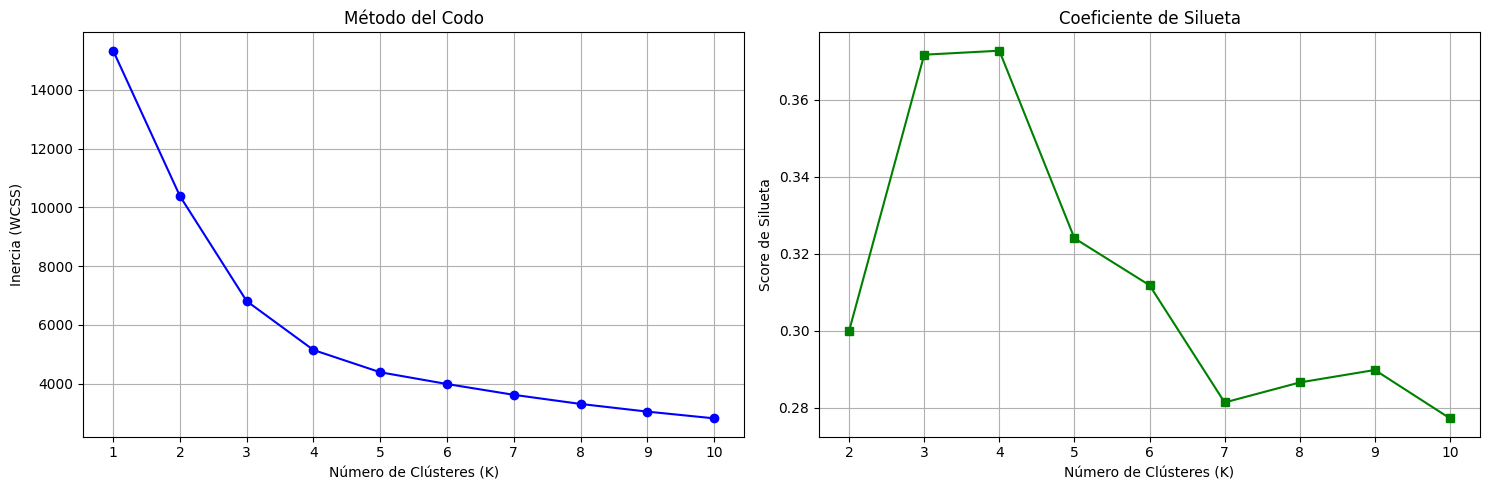

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Listas para guardar las métricas
inercia = []
silueta = []

# Rango de K a evaluar
rango_k = range(1, 11)
rango_k_silueta = range(2, 11) # Silueta requiere al menos 2 clústeres

# Calcular Inercia (Método del Codo)
for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)

# Calcular Coeficiente de Silueta
for k in rango_k_silueta:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_scaled)
    silueta.append(silhouette_score(X_scaled, etiquetas))

# Graficar resultados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfica del Método del Codo
ax1.plot(rango_k, inercia, marker='o', linestyle='-', color='b')
ax1.set_title('Método del Codo')
ax1.set_xlabel('Número de Clústeres (K)')
ax1.set_ylabel('Inercia (WCSS)')
ax1.grid(True)
ax1.set_xticks(rango_k)

# Gráfica de Silueta
ax2.plot(rango_k_silueta, silueta, marker='s', linestyle='-', color='g')
ax2.set_title('Coeficiente de Silueta')
ax2.set_xlabel('Número de Clústeres (K)')
ax2.set_ylabel('Score de Silueta')
ax2.grid(True)
ax2.set_xticks(rango_k_silueta)

plt.tight_layout()
plt.show()

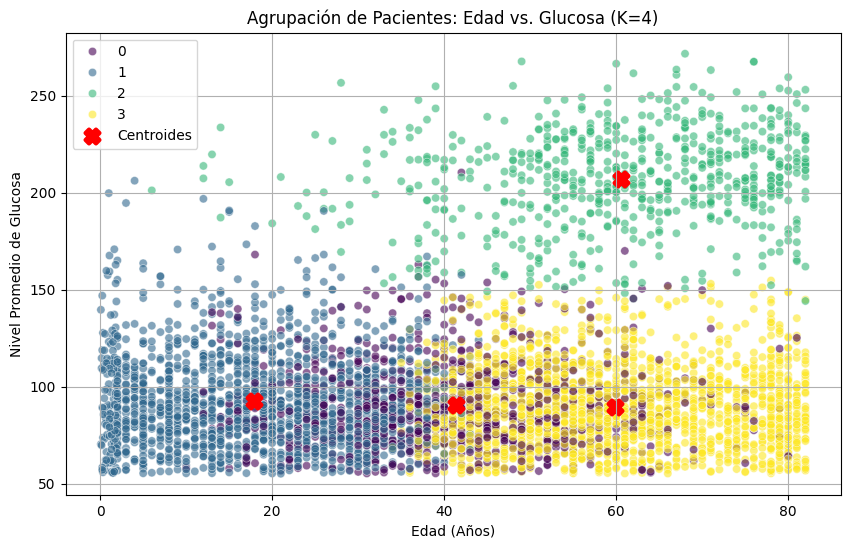

In [ ]:
import seaborn as sns

# 1. Entrenar el modelo final con el número óptimo de clústeres (K=4)
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)

# Asignar la etiqueta del clúster a cada paciente en el DataFrame limpio original
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 2. Obtener las coordenadas de los centroides
centroides_escalados = kmeans_final.cluster_centers_

# Invertir el escalado de los centroides para graficarlos en la escala original (Años y Glucosa real)
centroides_originales = scaler.inverse_transform(centroides_escalados)

# 3. Crear el gráfico de dispersión
plt.figure(figsize=(10, 6))

# Dibujar a los pacientes coloreados por su clúster
sns.scatterplot(data=df_clean, x='age', y='avg_glucose_level', hue='Cluster', palette='viridis', alpha=0.6)

# Marcar los centroides con una "X" roja gigante (índices 0 y 1 corresponden a age y avg_glucose_level)
plt.scatter(centroides_originales[:, 0], centroides_originales[:, 1],
            s=100, c='red', marker='X', label='Centroides', linewidths=3)

plt.title('Agrupación de Pacientes: Edad vs. Glucosa (K=4)')
plt.xlabel('Edad (Años)')
plt.ylabel('Nivel Promedio de Glucosa')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 1. Unir la columna 'stroke' real al DataFrame con los clústeres
df_clean['stroke_real'] = stroke_real

# 2. Crear una tabla cruzada entre los Clústeres (filas) y la variable real 'stroke' (columnas)
tabla_cruzada = pd.crosstab(df_clean['Cluster'], df_clean['stroke_real'], margins=True)
print("--- Tabla Cruzada: Clúster vs Derrame Cerebral ---")
display(tabla_cruzada)

# 3. Calcular el porcentaje de derrames dentro de cada clúster para ver la concentración de riesgo
# Al sacar el promedio de una columna de 0s y 1s, obtenemos la proporción de casos positivos.
porcentajes_riesgo = df_clean.groupby('Cluster')['stroke_real'].mean() * 100
print("\n--- Porcentaje de casos de derrame dentro de cada clúster ---")
print(porcentajes_riesgo.round(2).astype(str) + ' %')

--- Tabla Cruzada: Clúster vs Derrame Cerebral ---


stroke_real,0,1,All
Cluster,,,
0,891,15,906
1,1633,4,1637
2,583,89,672
3,1754,141,1895
All,4861,249,5110



--- Porcentaje de casos de derrame dentro de cada clúster ---
Cluster
0     1.66 %
1     0.24 %
2    13.24 %
3     7.44 %
Name: stroke_real, dtype: object
